# Working with Sequences

We start the practice by installing the book libraries and importing some of them:

In [118]:
import torch
from torch import nn
from d2l import torch as d2l
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

## Autoregressive Models

Our target data will be a synthetic data set built on the sinusoidal function SIN. We create 1000 data points within the DATA class but corrupt their values by adding some random noise.

```python
self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2
```

We first define some initialization parameters:

- Batch size = 16
- T = 1000 (size of the sequence)
- num_train (training samples)
- tau = 4 (4 points will be used to estimate our next sample) (Markov problem of order 4)

In [119]:
class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        self.save_hyperparameters()
        self.time = torch.arange(1, T + 1, dtype=torch.float32)
        self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2

Let's verify the type pof structure we are using (Torch Tensors) and print the created data.

<class 'torch.Tensor'>
<class 'torch.Tensor'>


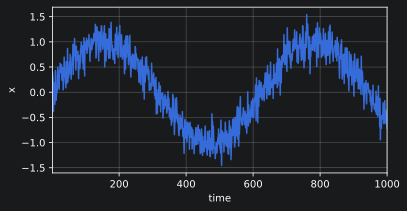

In [120]:
data = Data()
print(type(data.time))
print(type(data.x))
d2l.plot(data.time, data.x, "time", "x", xlim=[1, 1000], figsize=(6, 3))

To begin, we try a model that acts as if the data satisfied a $\tau^{\textrm{th}}$-order Markov condition, and thus predicts $x_t$ using only the past $\tau$ observations. (We set it up originally to 4, you should try other values as well).

[**Thus for each time step we have an example with label $y  = x_t$ and features $\mathbf{x}_t = [x_{t-\tau}, \ldots, x_{t-1}]$.**]


In [121]:
@d2l.add_to_class(Data)
def get_dataloader(self, train):
    features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
    self.features = torch.stack(features, 1)
    self.labels = self.x[self.tau:].reshape((-1, 1))
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader([self.features, self.labels], train, i)

In this example our model will be a simple standard linear regression. You can consult early chapters of the book "Dive into DL" (D2l)  to see some more details of it. At this moment, we are not much interesting on the model used. We will analyze relevant models later.

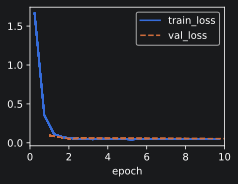

In [122]:
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

## Prediction

To evaluate our model, we first check how well it performs at one-step-ahead prediction.

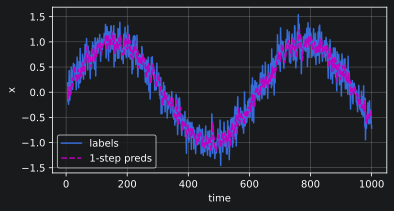

In [123]:
onestep_preds = model(data.features).detach().numpy()
d2l.plot(data.time[data.tau:], [data.labels, onestep_preds], "time", "x", legend=["labels", "1-step preds"], figsize=(6, 3))

These predictions look good, even near the end at $t=1000$.

But what if we only observed sequence data up until time step 604 (`n_train + tau`) and wished to make predictions several steps into the future? Unfortunately, we cannot directly compute the one-step-ahead prediction for time step 609, because we do not know the corresponding inputs, having seen only up to $x_{604}$. We can address this problem by plugging in our earlier predictions as inputs to our model for making subsequent predictions, projecting forward, one step at a time, until reaching the desired time step:

$$\begin{aligned}
\hat{x}_{605} &= f(x_{601}, x_{602}, x_{603}, x_{604}), \\
\hat{x}_{606} &= f(x_{602}, x_{603}, x_{604}, \hat{x}_{605}), \\
\hat{x}_{607} &= f(x_{603}, x_{604}, \hat{x}_{605}, \hat{x}_{606}),\\
\hat{x}_{608} &= f(x_{604}, \hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}),\\
\hat{x}_{609} &= f(\hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}, \hat{x}_{608}),\\
&\vdots\end{aligned}$$

Generally, for an observed sequence $x_1, \ldots, x_t$, its predicted output $\hat{x}_{t+k}$ at time step $t+k$ is called the $k$*-step-ahead prediction*. Since we have observed up to $x_{604}$, its $k$-step-ahead prediction is $\hat{x}_{604+k}$. In other words, we will have to keep on using our own predictions to make multistep-ahead predictions. Let's see how well this goes.

In [124]:
multistep_preds = torch.zeros(data.T)
multistep_preds[:] = data.x
for i in range(data.num_train + data.tau, data.T):
    multistep_preds[i] = model(multistep_preds[i - data.tau:i].reshape((1, -1)))
multistep_preds = multistep_preds.detach().numpy()

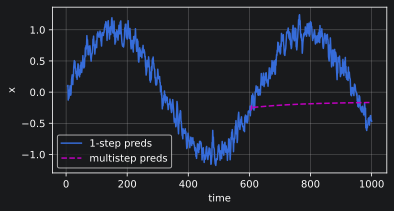

In [125]:
d2l.plot([data.time[data.tau:], data.time[data.num_train+data.tau:]],
         [onestep_preds, multistep_preds[data.num_train+data.tau:]], "time",
         "x", legend=["1-step preds", "multistep preds"], figsize=(6, 3))

Unfortunately, in this case we fail spectacularly. The predictions decay to a constant pretty quickly after a few steps. Why did the algorithm perform so much worse when predicting further into the future? Ultimately, this is down to the fact that errors build up. Let's say that after step 1 we have some error $\epsilon_1 = \bar\epsilon$. Now the *input* for step 2 is perturbed by $\epsilon_1$, hence we suffer some error in the order of $\epsilon_2 = \bar\epsilon + c \epsilon_1$ for some constant $c$, and so on. The predictions can diverge rapidly from the true observations. You may already be familiar with this common phenomenon. For instance, weather forecasts for the next 24 hours tend to be pretty accurate but beyond that, accuracy declines rapidly. We will discuss methods for improving this throughout this chapter and beyond.

Let's [**take a closer look at the difficulties in $k$-step-ahead predictions**] by computing predictions on the entire sequence for $k = 1, 4, 16, 64$.

In [126]:
def k_step_pred(k, model):
    features = []
    for i in range(data.tau):
        features.append(data.x[i : i+data.T-data.tau-k+1])
    # The (i+tau)-th element stores the (i+1)-step-ahead predictions
    for i in range(k):
        preds = model(torch.stack(features[i : i+data.tau], 1))
        features.append(preds.reshape(-1))
    return features[data.tau:]

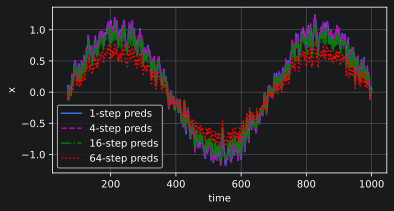

In [127]:
steps = (1, 4, 16, 64)
preds = k_step_pred(steps[-1], model)
d2l.plot(data.time[data.tau+steps[-1]-1:],
         [preds[k - 1].detach().numpy() for k in steps], "time", "x",
         legend=[f"{k}-step preds" for k in steps], figsize=(6, 3))

This clearly illustrates how the quality of the prediction changes as we try to predict further into the future. While the 4-step-ahead predictions still look good, anything beyond that is starts to get worse.

## P0-Exercises

1. Improve the model in the experiment of this section. Modify the number of past observations used for predictions. What seems to be the optimal value? Justify.
2. With a chosen value of $\tau$ compare results for future predictions at different times, showing the error obtained.
3. Repeat the whole analysis with a real data set:
    - Option a) ibm.us.txt : Stock Market predictions
    - Option b) daily-min-temperaturas.csv : Daily Temperature values

    Extract conclusions. Compute the MSE o MAE for different cases.
4. Theory: Autoregressive vs Autoregressive latent models. Look for an example that might need latent variables to capture the dynamic of the data. Explain.

### Ejercicio 1

Vamos a analizar el impacto del tamaño de la memoria temporal del modelo ($\tau$) sobre la precisión de las predicciones a 1 paso hacia adelante (1-step-ahead prediction).

Para determinar el número óptimo de observaciones pasadas necesarias para predecir el siguiente valor $x_t$, evaluamos el modelo de regresión lineal para distintos valores de $\tau \in \{1, 2, 4, 8, 16, 32, 64\}$. Analizaremos el comportamiento del error cuadrático medio (MSE) para concluir con qué valor de $\tau$ optimizamos el rendimiento del modelo.

,tau,mse
0,1,0.071776
1,2,0.063374
2,4,0.053319
3,8,0.049197
4,16,0.059052
5,32,0.054858
6,64,0.050841


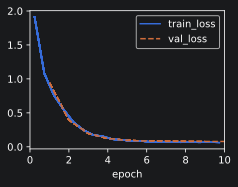

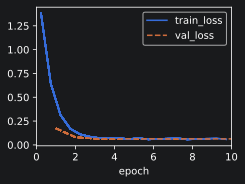

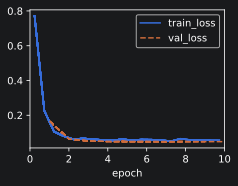

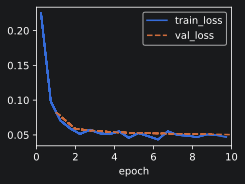

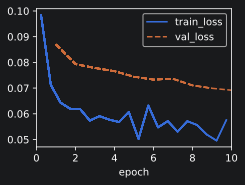

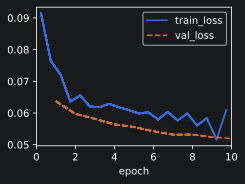

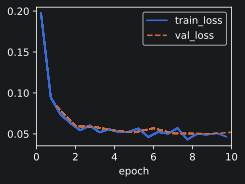

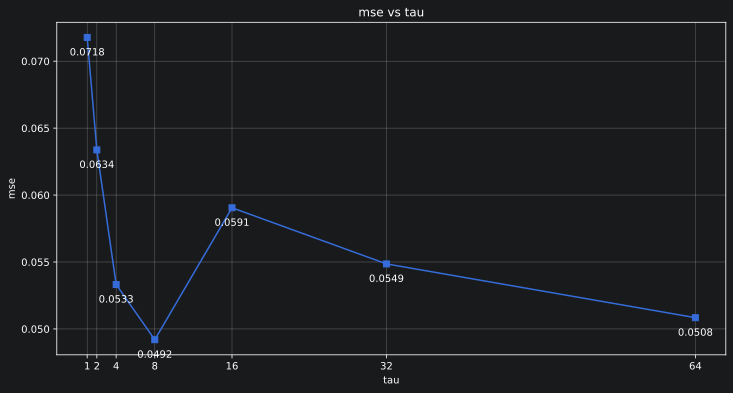

In [128]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

tau_values = [1, 2, 4, 8, 16, 32, 64]
res = []

for t in tau_values:
    data = Data(tau=t)

    model = d2l.LinearRegression(lr=0.01)
    trainer = d2l.Trainer(max_epochs=10)
    trainer.fit(model, data)
    pred = model(data.features)
    mse = torch.mean((data.labels - pred) ** 2).item()
    res.append({
        "tau": t,
        "mse": mse,
    })

res = pd.DataFrame(res)
display(res)

plt.show()
plt.figure(figsize=(12, 6))
plt.plot(res["tau"], res["mse"] , marker="s")
plt.xticks(res["tau"])
for t, mse in zip(res["tau"], res["mse"]):
    plt.annotate(
        f"{mse:.4f}",
        (t, mse),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
    )
plt.xlabel("tau")
plt.ylabel("mse")
plt.title("mse vs tau")
plt.grid()
plt.show()

Tras evaluar el rendimiento frente a diferentes órdenes de Markov ($\tau$), se observan los siguientes comportamientos clave:
- $\tau = 1$ (MSE = 0.0718): presenta el mayor nivel de error respecto a los demás, ya que con un solo dato histórico no se puede determinar la trayectoria de la onda.
- $\tau = 2$ a $\tau = 4$: el error disminuye notablemente ($0.0634$ y $0.0533$). Con $\tau \ge 2$, el modelo pasa a capturar la velocidad y dirección de la señal de segundo orden.
- $\tau = 8$ (MSE = 0.0492): se alcanza el mínimo global de error. Disponer de 8 observaciones históricas permite a la regresión lineal filtrar eficazmente el ruido sin sobrecargar la entrada.
- $\tau \ge 16$: en $\tau = 16$ el error sufre un repunte ($0.0591$) y posteriormente vuelve a descender progresivamente hasta $0.0508$ en $\tau = 64$. Sin embargo, las curvas de error se vuelven más ruidosas y ningún valor posterior logra superar la precisión obtenida en $\tau = 8$.

El valor óptimo en esta ejecución es $\tau = 8$, ya que logra la mayor capacidad de predicción minimizando el error, sin necesidad de aumentar la complejidad paramétrica del modelo ni descartar más datos iniciales.

Veamos ahora de forma gráfica como predice:

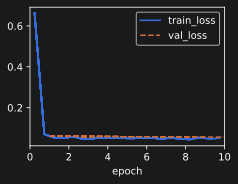

In [129]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

TAU = 8
data = Data(tau=TAU)
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

pred = model(data.features).detach().numpy()

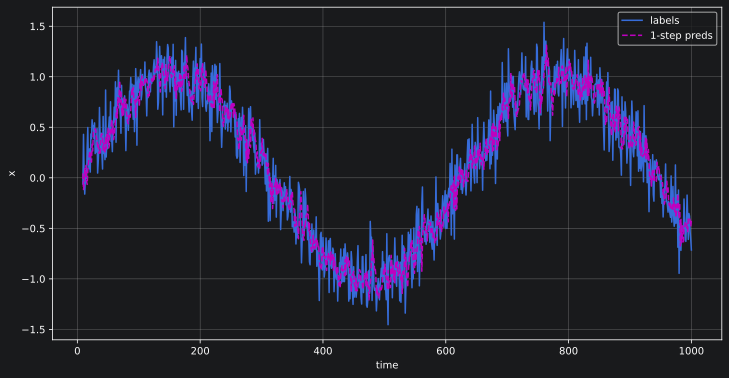

In [130]:
d2l.plot(data.time[data.tau :], [data.labels, pred], "time", "x", legend=["labels", "1-step preds"], figsize=(12, 6))

### Ejercicio 2

Vamos a evaluar la evolución del error al realizar predicciones a varios pasos hacia el futuro fijando el tamaño de ventana óptimo obtenido en el Ejercicio 1 ($\tau$ = 8).

A diferencia de la predicción a 1 paso (donde el modelo siempre recibe observaciones reales pasadas), al predecir a k pasos el modelo debe alimentarse recursivamente de sus propias predicciones anteriores. Vamos a ver el proceso de acumulación y propagación del error con distintos valores de k $\in \{1, 2, 4, 8, 16, 32, 64\}$.

,k (steps),mse
0,1,0.979162
1,2,0.980942
2,4,0.986769
3,8,0.994519
4,16,1.016160
5,32,1.061264
6,64,1.156941


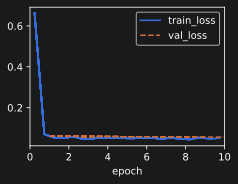

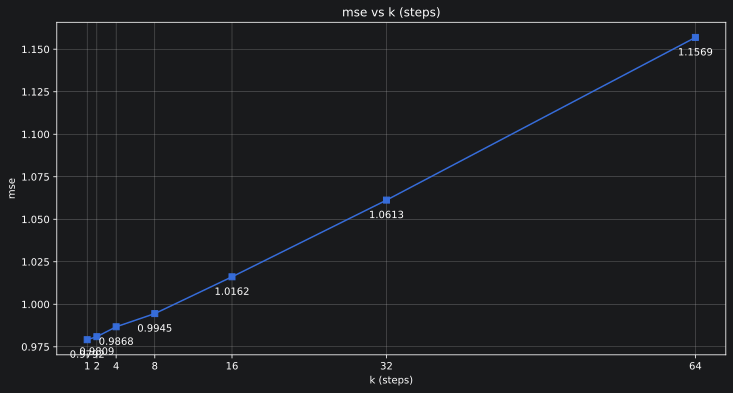

In [131]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

data = Data(tau=TAU)
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

k_values = [1, 2, 4, 8, 16, 32, 64]
res = []
preds = k_step_pred(k_values[-1], model)

for k in k_values:
    pred = preds[k - 1]
    labels_k = data.x[data.tau + k - 1 : data.T].reshape(-1, 1)
    pred_k_aligned = pred[:len(labels_k)]
    mse = torch.mean((labels_k - pred_k_aligned) ** 2).item()
    res.append({
        "k (steps)": k,
        "mse": mse,
    })

res = pd.DataFrame(res)
display(res)
plt.figure(figsize=(12, 6))
plt.plot(res["k (steps)"], res["mse"] , marker="s")
plt.xticks(res["k (steps)"])
for k, mse in zip(res["k (steps)"], res["mse"]):
    plt.annotate(
        f"{mse:.4f}",
        (k, mse),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
    )
plt.xlabel("k (steps)")
plt.ylabel("mse")
plt.title("mse vs k (steps)")
plt.grid()
plt.show()

A partir de los datos representados en la curva de error, se identifican tres tramos claros en la degradación del modelo:

- k = 1 a k = 8: el incremento del error es mínimo, pasando de MSE = 0.9791 en k = 1 a MSE = 0.9945 en k = 8. En esta franja, el modelo mantiene un rendimiento muy robusto.
- k = 16: el error sube a MSE = 1.0162. Al superar el tamaño de ventana $\tau$ = 8, el modelo empieza a alimentarse en su totalidad de sus propias predicciones intermedias.
- k = 32 y k = 64: El error se dispara hasta MSE = 1.0613 en k = 32 y alcanza un máximo de MSE = 1.1569 en k = 64.

Numéricamente, el error no crece de forma lineal sino acelerada. Esto confirma que el límite de fiabilidad del modelo autorregresivo se sitúa en k $\le$ 8.

Analicemos ahora las gráficas predichas una sobre otra para ver visualmente el aumento del error:

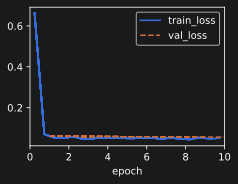

In [132]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

data = Data(tau=TAU)
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

steps = [1, 4, 16, 64]
preds = k_step_pred(steps[-1], model)

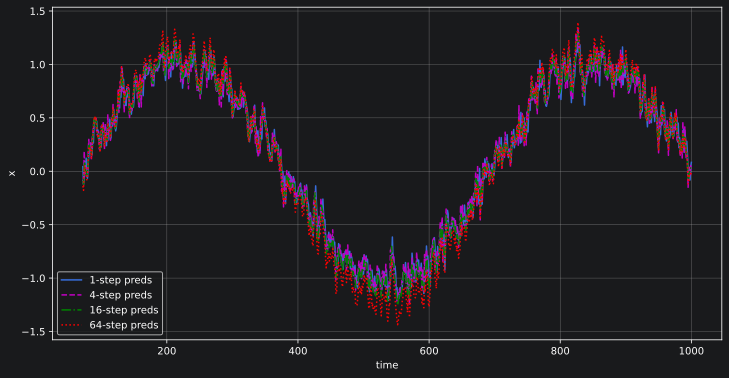

In [133]:
d2l.plot(data.time[data.tau + steps[-1] - 1 :], [preds[k - 1].detach().numpy() for k in steps], "time", "x", legend=[f"{k}-step preds" for k in steps], figsize=(12, 6))

Vemos que la curva azul es la más fiel a la original, mientras que si vamos aumentando el valor de k, se aumenta el tamaño de los picos y cada vez es más ruidoso. Con ello se demuestra la degradación por acumulación de error.

### Ejercicio 3

A continuación vamos a replicar la misma metodología de los Ejercicios 1 y 2 sobre la serie temporal `daily-min-temperaturas.csv`.

1. Estandarización (Z-score): se transforma la serie de temperaturas $x$ a media $\mu$ = 0 y desviación estándar $\sigma$ = 1:
   $$x_{\text{norm}} = \frac{x - \mu}{\sigma}$$
2. Evaluación de $\tau$ (Predicción a 1 paso): se mide el error cuadrático medio (MSE) sobre el conjunto de prueba para $\tau \in \{1, 2, 4, 8, 16, 32, 64\}$ para seleccionar el valor óptimo.
3. Evaluación del horizonte k (Predicción autorregresiva): con el $\tau$ óptimo seleccionado, se evalúa la degradación de las predicciones a k pasos (k $\in \{1 \dots 64\}$) y la pérdida de variabilidad local a largo plazo.

Todo el procedimiento es el mismo que antes, por lo que solo vamos a explicar los resultados:

In [134]:
df = pd.read_csv("../data/daily-min-temperatures.csv")

temp = df["Temp"]
temp_norm = (temp - temp.mean()) / temp.std()

In [135]:
class TempDataset(d2l.DataModule):
    def __init__(self, data, tau=8, num_train=2750, batch_size=32):
        super().__init__()
        self.save_hyperparameters()
        self.T = len(data)
        self.time = torch.arange(0, self.T, dtype=torch.float32)
        self.x = torch.tensor(data.to_numpy(), dtype=torch.float32)

    def get_dataloader(self, train):
        features = [self.x[i : self.T - self.tau + i] for i in range(self.tau)]
        self.features = torch.stack(features, 1)
        self.labels = self.x[self.tau:].reshape((-1, 1))
        i = slice(0, self.num_train) if train else slice(self.num_train, None)
        return self.get_tensorloader([self.features, self.labels], train, i)

In [136]:
def k_step_pred_temp(k, model, data):
    features = data.features.clone()
    preds = []
    for _ in range(k):
        pred = model(features)
        preds.append(pred)
        features = torch.cat((features[:, 1:], pred), dim=1)
    return preds

,tau,mse
0,1,0.399023
1,2,0.396919
2,4,0.373767
3,8,0.357350
4,16,0.350338
5,32,0.348863
6,64,0.342192


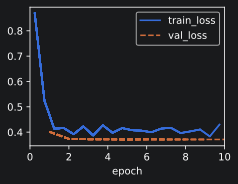

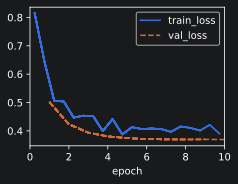

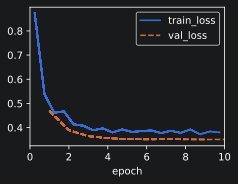

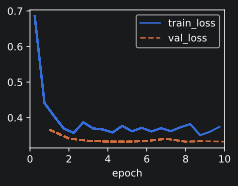

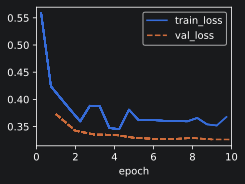

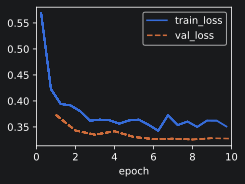

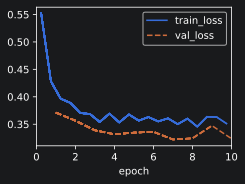

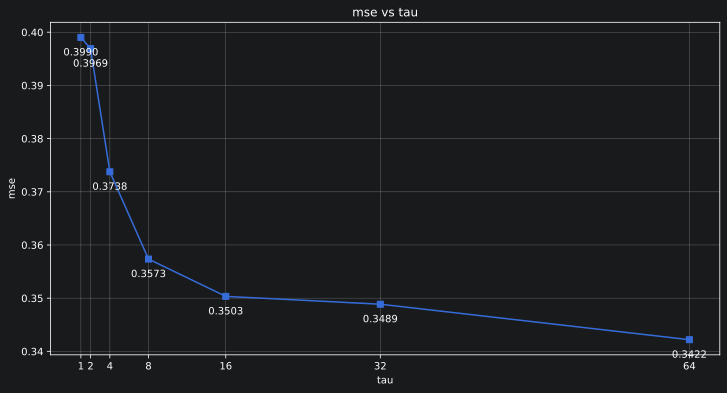

In [137]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

tau_values = [1, 2, 4, 8, 16, 32, 64]
res = []

for t in tau_values:
    data = TempDataset(temp_norm, tau=t)

    model = d2l.LinearRegression(lr=0.01)
    trainer = d2l.Trainer(max_epochs=10)
    trainer.fit(model, data)
    pred = model(data.features)
    mse = torch.mean((data.labels - pred) ** 2).item()
    res.append({
        "tau": t,
        "mse": mse,
    })

res = pd.DataFrame(res)
display(res)

plt.show()
plt.figure(figsize=(12, 6))
plt.plot(res["tau"], res["mse"] , marker="s")
plt.xticks(res["tau"])
for t, mse in zip(res["tau"], res["mse"]):
    plt.annotate(
        f"{mse:.4f}",
        (t, mse),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
    )
plt.xlabel("tau")
plt.ylabel("mse")
plt.title("mse vs tau")
plt.grid()
plt.show()

En este caso no se ve tan claro cuál es el valor óptimo de $\tau$. Para ello vamos a aplicar el criterio del codo:
* Entre $\tau$ = 1 y $\tau$ = 8 se produce la mayor reducción del error 0.3990 a 0.3573, capturando.
* A partir de $\tau$ = 8, incrementar la ventana a $\tau = 16$ o $\tau = 32$ ofrece ganancias insignificantes en el MSE ($\le$ 0.0070) a costa de aumentar la complejidad computacional y reducir el número de muestras efectivas de entrenamiento.

Por ello elegiremos un valor de $\tau$ = 8.

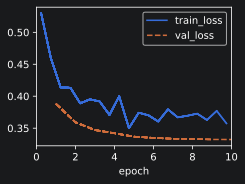

In [138]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

TAU = 8
data = TempDataset(temp_norm, tau=TAU)
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

pred = model(data.features).detach().numpy()

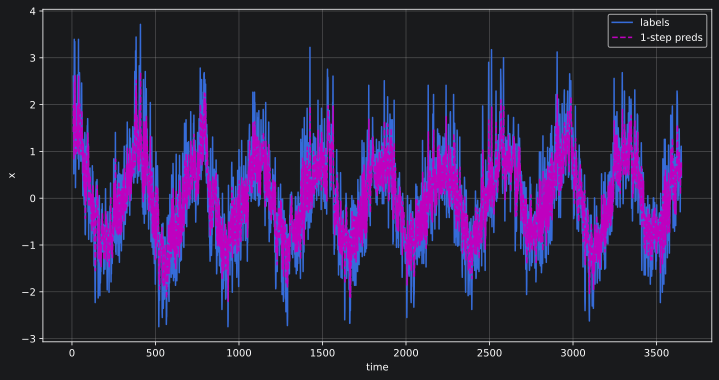

In [139]:
d2l.plot(data.time[data.tau :], [data.labels, pred], "time", "x", legend=["labels", "1-step preds"], figsize=(12, 6))

Podemos ver que sigue la tendencia de la serie, pero hay algunos picos que no llega a detectar y se queda corto.

,k (steps),mse
0,1,0.357665
1,2,0.491445
2,4,0.533634
3,8,0.570454
4,16,0.614700
5,32,0.744126
6,64,0.918670


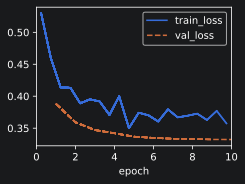

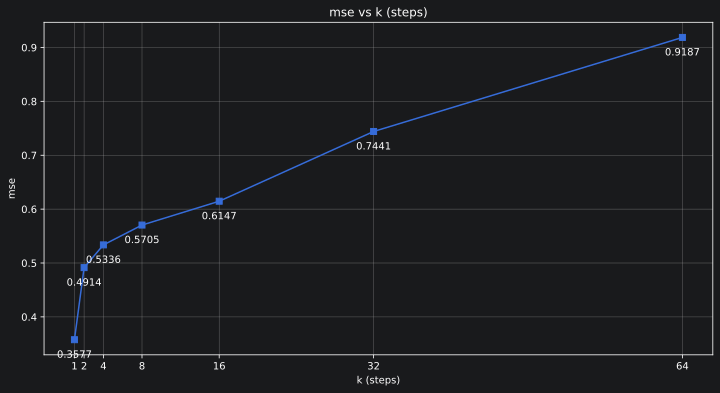

In [140]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

data = TempDataset(temp_norm, tau=TAU)
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

k_values = [1, 2, 4, 8, 16, 32, 64]
res = []
preds = k_step_pred_temp(k_values[-1], model, data)

for k in k_values:
    pred = preds[k - 1]
    labels_k = data.x[data.tau + k - 1 : data.T].reshape(-1, 1)
    pred_k_aligned = pred[: len(labels_k)]
    mse = torch.mean((labels_k - pred_k_aligned) ** 2).item()
    res.append({
        "k (steps)": k,
        "mse": mse,
    })

res = pd.DataFrame(res)
display(res)
plt.figure(figsize=(12, 6))
plt.plot(res["k (steps)"], res["mse"] , marker="s")
plt.xticks(res["k (steps)"])
for k, mse in zip(res["k (steps)"], res["mse"]):
    plt.annotate(
        f"{mse:.4f}",
        (k, mse),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
    )
plt.xlabel("k (steps)")
plt.ylabel("mse")
plt.title("mse vs k (steps)")
plt.grid()
plt.show()

El MSE aumenta de forma continua desde 0.3577 (k = 1) hasta 0.9187 (k = 64) debido a la acumulación recursiva de errores. Conforme k aumenta, la predicción pierde la variabilidad diaria y converge a la media de la serie ($\mu$ = 0), haciendo que el error se aproxime a 1, la varianza total de los datos estandarizados.

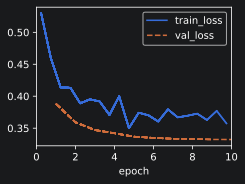

In [141]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

data = TempDataset(temp_norm, tau=TAU)
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

steps = [1, 4, 16, 64]
preds = k_step_pred_temp(steps[-1], model, data)

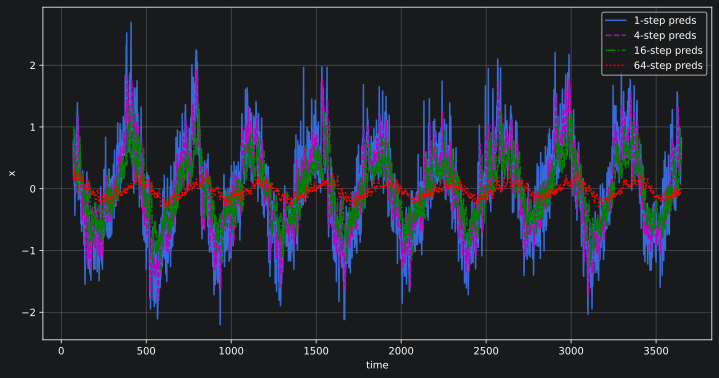

In [142]:
d2l.plot(data.time[data.tau + steps[-1] - 1 : len(data.x)], [preds[k - 1][steps[-1] - k : len(data.x) - data.tau - k + 1].detach().numpy() for k in steps], "time", "x", legend=[f"{k}-step preds" for k in steps], figsize=(12, 6))

A medida que aumenta k, la trayectoria predicha sufre apalstamiento de la varianza. Mientras que k = 1 y k = 4 capturan bien, k = 16 y k = 64 filtran el ruido local y colapsan hacia la media de la serie ($\mu$ = 0). Pierde capacidad de estimar a mucho tiempo para valores altos y lo que hace es un promedio.

### Ejercicio 4

Diferencias entre modelos autorregresivos y modelos de variable latente:
- Modelos autorregresivos: asumen la propiedad de Markov de orden $\tau$, prediciendo el valor futuro $x_t$ a partir de un conjunto finito de observaciones pasadas directas ($x_{t-1}, \dots, x_{t-\tau}$). Carecen de memoria de estado global y requieren escalar el tamaño de la entrada para capturar contextos lejanos.
- Modelos de variable altente: introducen un estado oculto $h_t$ que evoluciona ($h_t = g(h_{t-1}, x_{t-1})$) y resume toda la secuencia histórica. Esto permite modelar dependencias de largo alcance y factores no observados del sistema sin incrementar el tamaño del vector de entrada.

Un ejemplo para poder entender la diferencia es el siguiente: supongamos que tenemos el GPS de un coche y vamos a cruzar un túnel:
- Lo observado ($x_t$): tenemos las coordenadas GPS del coche recibida cada segundo.
- La variable latente ($h_t$): tenemos la velocidad, dirección y aceleración real del coche.

Si el coche entra en el túnel, pierde la señal del GPS durante un tiempo, un modelo autorregresivo que solo mira los últimos puntos GPS observados ($\tau$) se queda a ciegas y no puede seguir actualizando la posición. La variable latente ($h_t$) almacena en su memoria interna la velocidad y dirección a la que circulaba el coche antes de perder la cobertura. Gracias a este estado oculto, el sistema puede seguir estimando la posición del vehículo dentro del túnel paso a paso, aunque no esté recibiendo ninguna observación GPS directa ($x_t$).